# Phase 1 Complete Analysis — Medical Cost Personal Dataset (`insurance`)

**Source:** [Kaggle (`mirichoi0218/insurance`)](https://www.kaggle.com/datasets/mirichoi0218/insurance) / [Direct CSV](https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv)  
**Domain & Goal:** Individual health insurance billing dataset (`1,338` raw rows × `7` columns; target: `charges` in USD). We clean duplicate records, profile demographic and health attributes (`age`, `sex`, `bmi`, `children`, `smoker`, `region`), visualize univariate and bivariate distributions, and evaluate skewness transformations.

---
## 1. Dataset Overview & Semantic Column Profiling
**What we did & why:** We loaded the raw CSV using string-first two-pass ingestion (`ads.ingestion.load_csv`) so pandas never silently coerces formatting quirks, verified the raw file SHA-256 checksum, and classified every column into one of 10 semantic types (`numeric_continuous`, `numeric_discrete`, `binary`, `categorical_nominal`, `categorical_ordinal`, `datetime`, `id_like`, `free_text`, `constant`, `unknown`).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

DATASET = "insurance"
OUT_DIR = Path("..") / "outputs" / DATASET
CLEAN_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned.csv"
IMPUTED_CSV = Path("..") / "data" / "cleaned" / f"{DATASET}_cleaned_imputed.csv"

prof = json.loads((OUT_DIR / "profile.json").read_text(encoding="utf-8"))
print(f"Dataset: {prof['dataset_name']} | Raw shape: {prof['n_rows']:,} rows x {prof['n_cols']} cols | Exact duplicates: {prof['n_duplicate_rows']}")
prof_df = pd.DataFrame(prof["columns"])[["name", "raw_dtype", "semantic_type", "pct_missing", "n_unique", "semantic_type_reason"]]
display(prof_df)

Dataset: insurance | Raw shape: 1,338 rows x 7 cols | Exact duplicates: 1


name,raw_dtype,semantic_type,pct_missing,n_unique,semantic_type_reason
age,int64,numeric_continuous,0.0%,47,"numeric values (100.0% parseable, 47 unique)"
sex,object,binary,0.0%,2,"binary string/mixed encoding (gender binary (Male/Female): ['female', 'male'])"
bmi,float64,numeric_continuous,0.0%,548,"numeric values (100.0% parseable, 548 unique)"
children,int64,numeric_discrete,0.0%,6,integer values with 6 unique levels (unique ratio 0.4%)
smoker,object,binary,0.0%,2,"binary string/mixed encoding (boolean-like (Yes/No/1/0): ['no', 'yes'])"
region,object,categorical_nominal,0.0%,4,string categorical with 4 normalized unique values (raw=4)
charges,float64,numeric_continuous,0.0%,1337,"numeric values (100.0% parseable, 1337 unique)"


## 2. Automated Data Cleaning & Step-by-Step Audit Log
**What we did & why:** We executed the 12-step deterministic cleaning pipeline (`ads.cleaning.clean_dataset`):
1. **Header & Whitespace/Unicode Normalization:** Stripped leading/trailing spaces and invisible characters.
2. **Missing Placeholder Normalization:** Converted placeholder tokens (`'?'`, `'N/A'`, `'null'`, `''`, and configured `'unknown'`) to `NaN`.
3. **Category Standardization & Type Conversion:** Unified case variants, parsed formatted numeric strings, and enforced domain validity ranges.
4. **Duplicate & Structural Drops:** Removed exact duplicate rows and redundant index/empty columns.
5. **Dual Missingness & Outlier Policy:** Saved both the **conservative primary dataset** (`_cleaned.csv`, preserving `NaN` and flagging $1.5\times\text{IQR}$ outliers without deleting valid extremes) and the **imputed secondary dataset** (`_cleaned_imputed.csv` with `__was_missing` indicator flags).

In [2]:
# Display the step-by-step cleaning audit log with before/after cell examples
display(Markdown((OUT_DIR / "cleaning_log.md").read_text(encoding="utf-8")))

# Cleaning Log — `insurance`

## Summary
2 cleaning step group(s) recorded; 0 column(s) type-converted; 0 cell(s) normalized (whitespace/missing tokens/categories); 1 duplicate row(s) removed; 0 row(s) dropped for structural/missingness rules.

## Step-by-Step Log

| Step | Column | Action | Severity | Cells Affected | Rows (Before -> After) | Reason | Examples (Before -> After) |
| :--- | :--- | :--- | :--- | ---: | ---: | :--- | :--- |
| `handle_duplicates` | *(table)* | `dropped_duplicate_rows` | info | 7 | 1338 -> 1337 | Dropped 1 exact duplicate row(s) (kept first occurrence). | - |
| `handle_outliers` | `bmi` | `flagged_outliers` | info | 0 | 1337 -> 1337 | Flagged 9 outlier(s) (0.7%) and 0 extreme outlier(s) in 'bmi' (action=flag; values untouched). | `49.06` -> `49.06`; `48.07` -> `48.07`; `47.52` -> `47.52` |
| `handle_outliers` | `charges` | `flagged_outliers` | info | 0 | 1337 -> 1337 | Flagged 139 outlier(s) (10.4%) and 6 extreme outlier(s) in 'charges' (action=flag; values untouched). | `39611.8` -> `39611.8`; `36837.5` -> `36837.5`; `37701.9` -> `37701.9` |


## 3. Cleaned Dataset Preview (Conservative vs. Imputed)
**What we did & why:** Below we inspect the first 5 rows and shapes of both the conservative cleaned dataset (`NaN` preserved for unbiased statistical testing) and the imputed dataset (median/mode imputed with `__was_missing` binary indicators).

In [3]:
df_clean = pd.read_csv(CLEAN_CSV)
df_imputed = pd.read_csv(IMPUTED_CSV)
print(f"Conservative cleaned shape: {df_clean.shape} | Imputed cleaned shape: {df_imputed.shape}")
display(df_clean.head(5))

Conservative cleaned shape: (1337, 7) | Imputed cleaned shape: (1337, 7)


age,sex,bmi,children,smoker,region,charges
19.0,female,27.900,0,yes,southwest,16884.92400
18.0,male,33.770,1,no,southeast,1725.55230
28.0,male,33.000,3,no,southeast,4449.46200
33.0,male,22.705,0,no,northwest,21984.47061
32.0,male,28.880,0,no,northwest,3866.85520


## 4. Exploratory Data Analysis (EDA) & Visualizations
**What we did & why:** Using `ads.eda.run_eda`, we generated 150-DPI static PNG visualizations covering dataset overview, missingness patterns, univariate numeric histograms + KDEs, IQR boxplots, categorical frequency distributions, target class balance, and bivariate relationships (Pearson $r$ / Spearman $\rho$ correlation heatmaps, bias-corrected Cramér's $V$, and $\eta^2$ group breakdowns). Every chart is paired below with a note explaining what it reveals about the data.

#### 7 columns; the most common type is numeric_continuous (3 columns)
*Figure 1. 7 columns; the most common type is numeric_continuous (3 columns).* Count of columns by the semantic type the pipeline inferred (after cleaning).


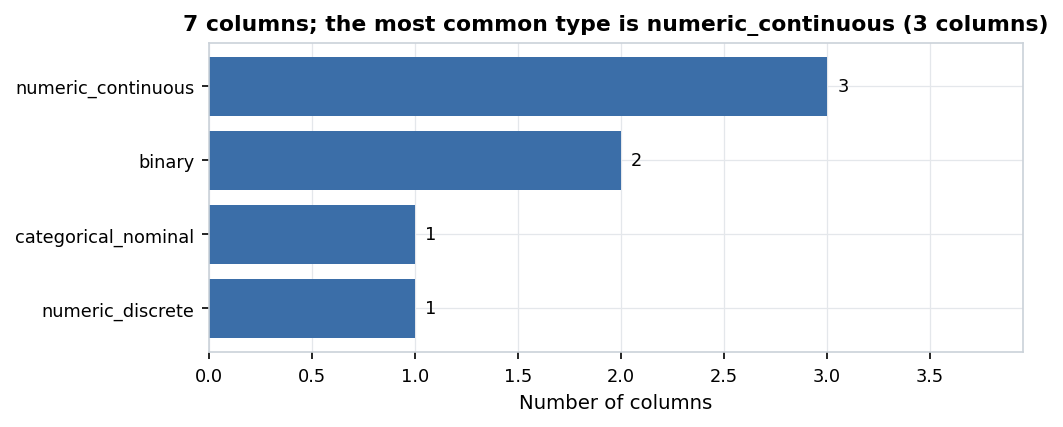

#### Numeric distributions (1/1): most skewed here is 'charges' (skew +1.51)
*Figure 2. Numeric distributions (1/1): most skewed here is 'charges' (skew +1.51).* Histogram (with a smooth density curve for many-valued columns) and a box plot per column. Orange line = mean, green dashed line = median; red dots are values beyond 1.5×IQR.


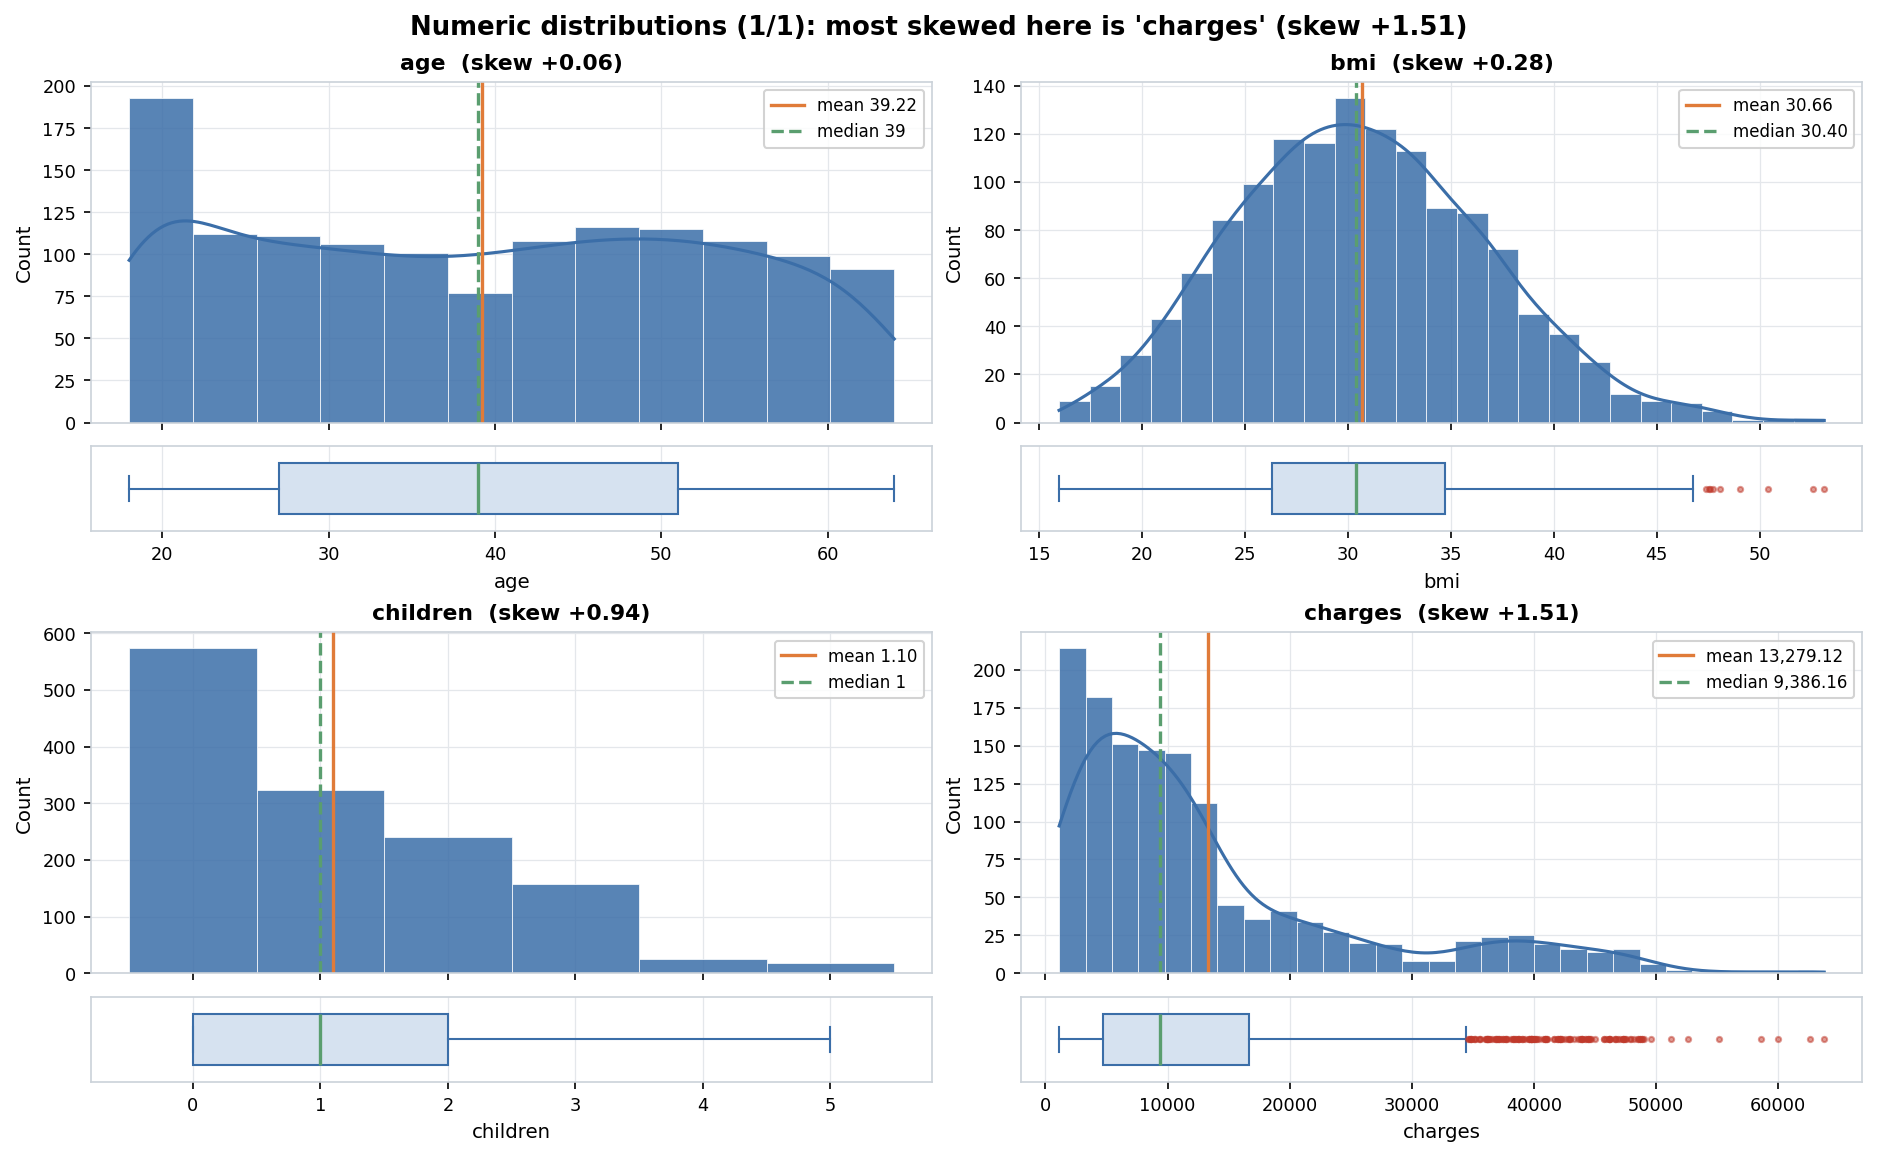

#### 'charges' is right-skewed (skew +1.51) and has 10.4% IQR outliers
*Figure 3. 'charges' is right-skewed (skew +1.51) and has 10.4% IQR outliers.* Close-up of a skewed or outlier-heavy column. The right panel shows the same values on a log1p scale.


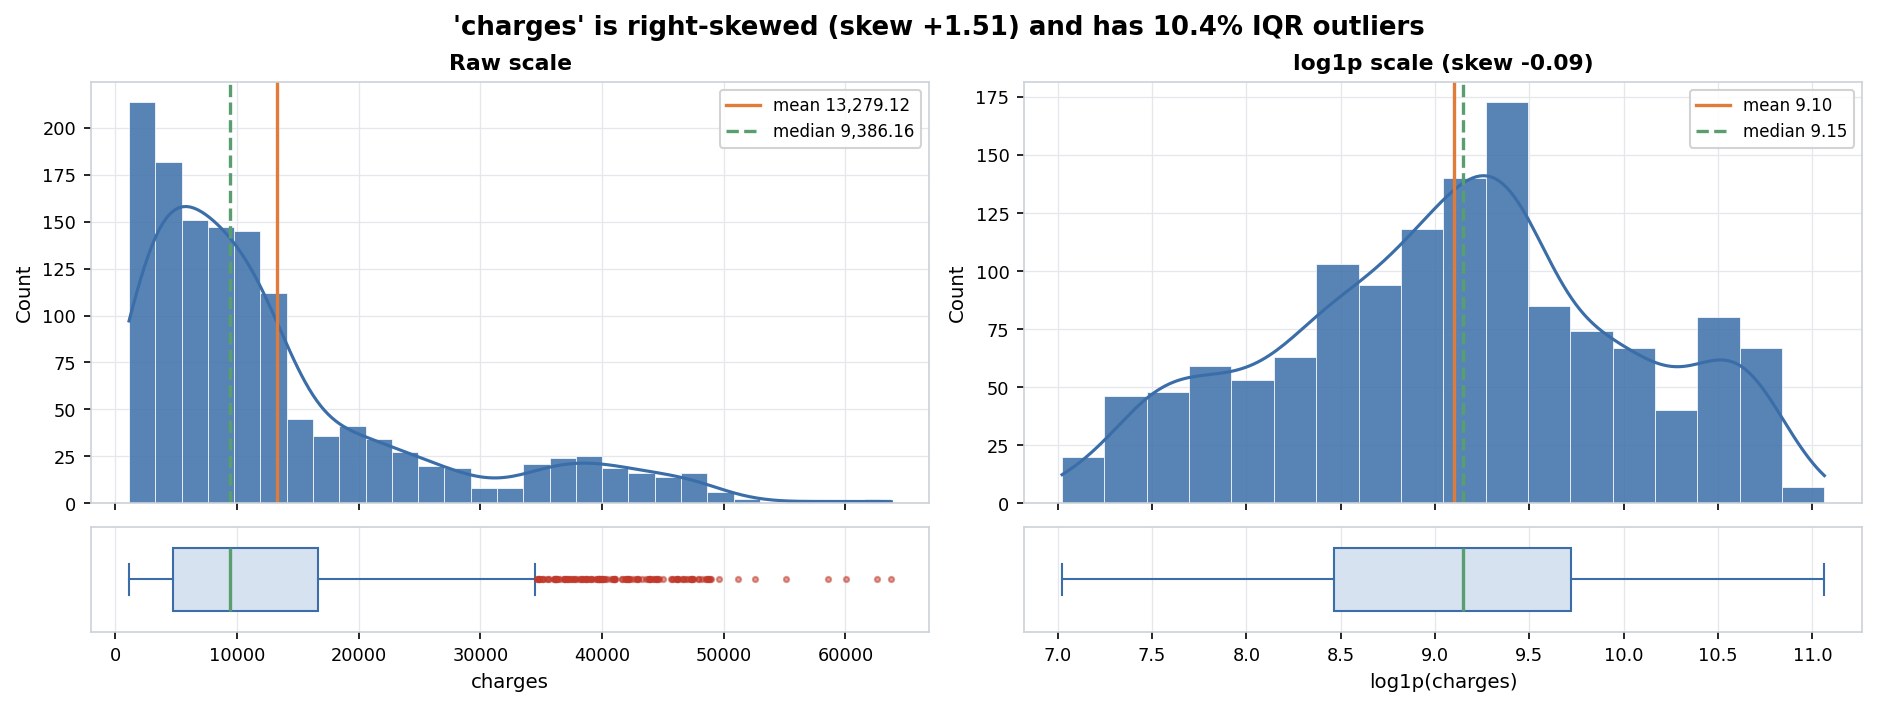

#### 'charges' has the most IQR outliers (10.4% of its values)
*Figure 4. 'charges' has the most IQR outliers (10.4% of its values).* Share of each numeric column's values outside 1.5×IQR. Outliers are only flagged, not removed, in the conservative cleaned data. Red bars are above the guide line.


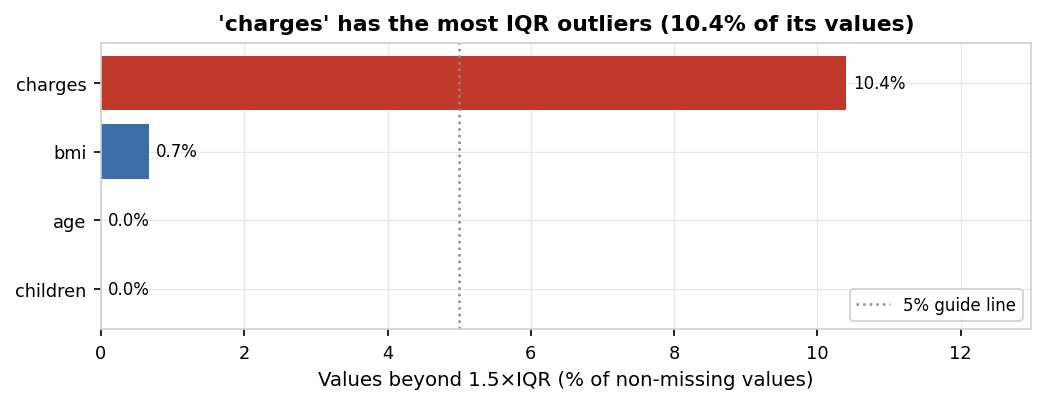

#### Categorical distributions (1/1): most lopsided here is 'smoker' (top level 79.5%)
*Figure 5. Categorical distributions (1/1): most lopsided here is 'smoker' (top level 79.5%).* Share of rows per level (top 15 levels; the rest are grouped as 'Other'). The orange bar marks the smallest (minority) level.


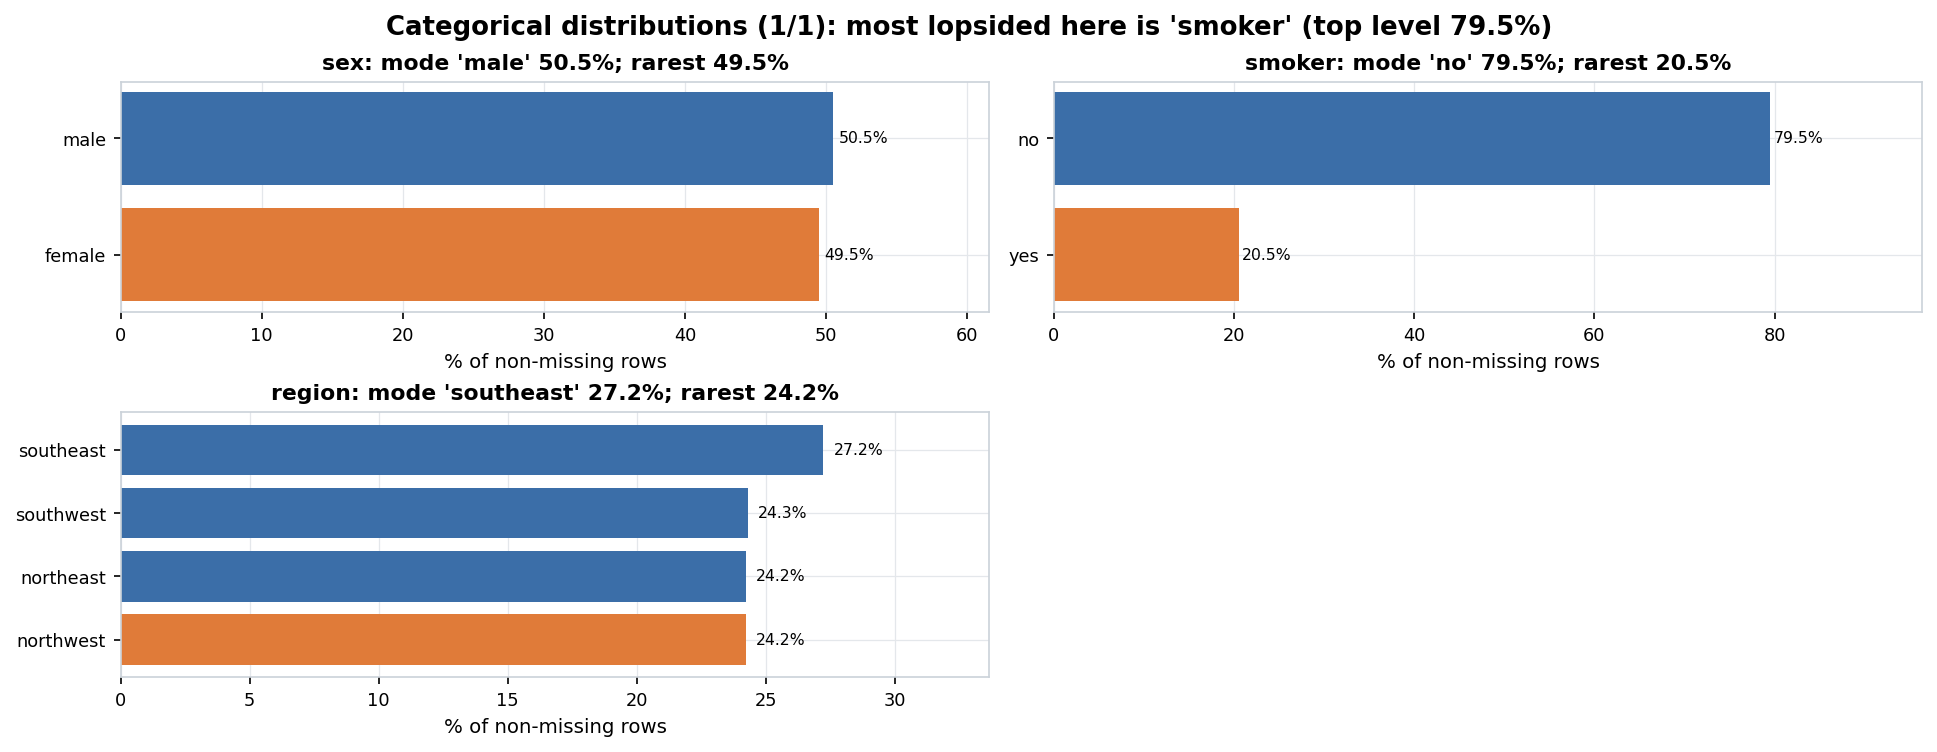

#### 'region' has the most levels (4)
*Figure 6. 'region' has the most levels (4).* Number of distinct values in each categorical or binary column.


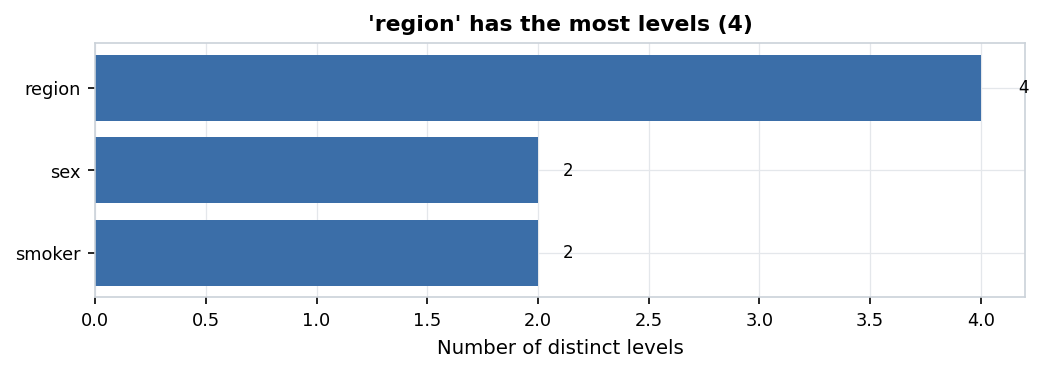

#### Target 'charges' ranges from 1,121.87 to 63,770.43 (median 9,386.16, skew +1.51)
*Figure 7. Target 'charges' ranges from 1,121.87 to 63,770.43 (median 9,386.16, skew +1.51).* Distribution of the target column.


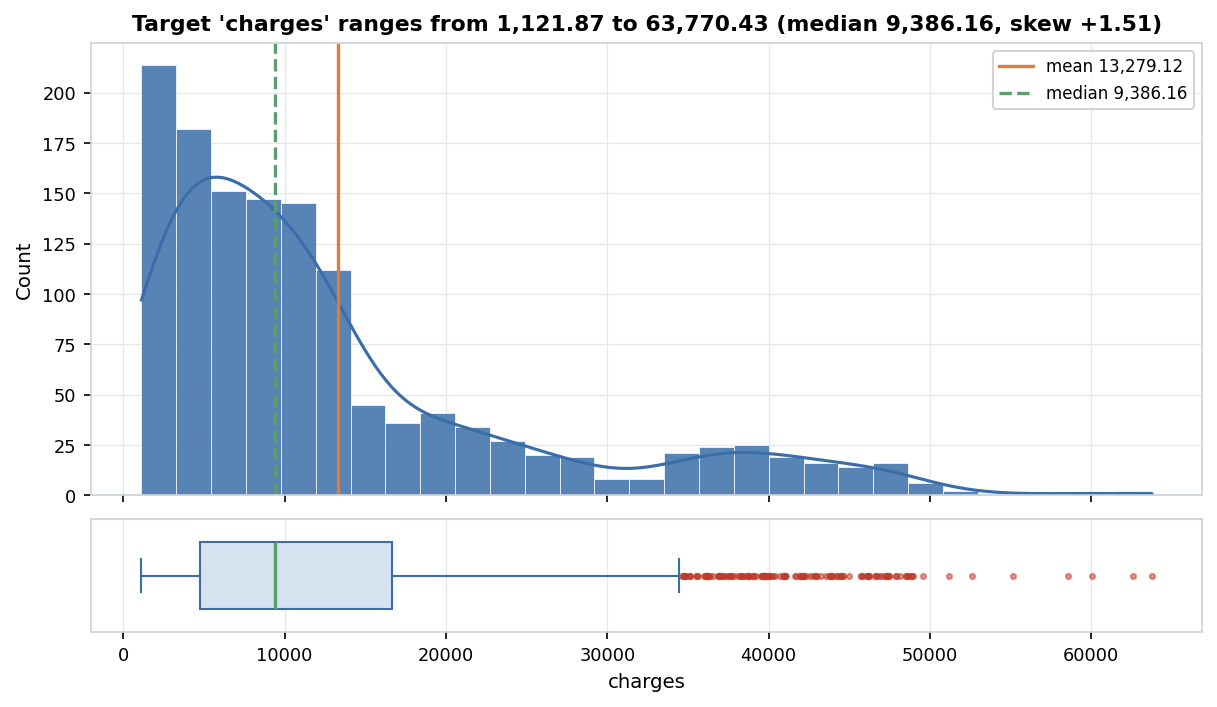

#### Strongest numeric pair: 'age' vs 'charges' (Spearman +0.53, Pearson +0.30)
*Figure 8. Strongest numeric pair: 'age' vs 'charges' (Spearman +0.53, Pearson +0.30).* Correlation between numeric columns (lower triangle). Left: Pearson (linear). Right: Spearman (rank-based). Descriptive coefficients only; no hypothesis tests were run.


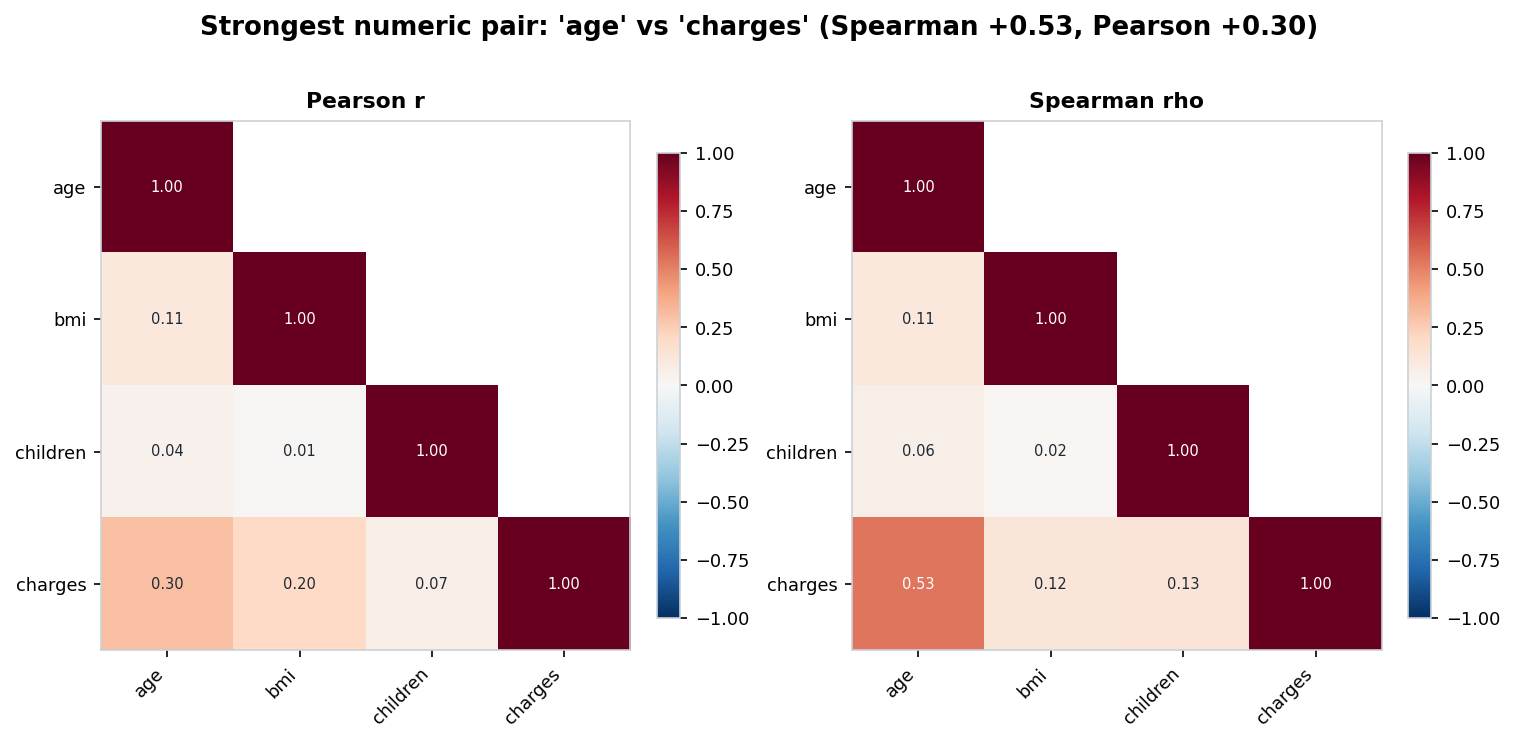

#### Top 6 numeric pairs by |Spearman rho|
*Figure 9. Top 6 numeric pairs by |Spearman rho|.* Scatter plots with a straight-line fit for the most strongly related numeric pairs. Large datasets are randomly sampled for plotting. Descriptive coefficients only; no hypothesis tests were run.


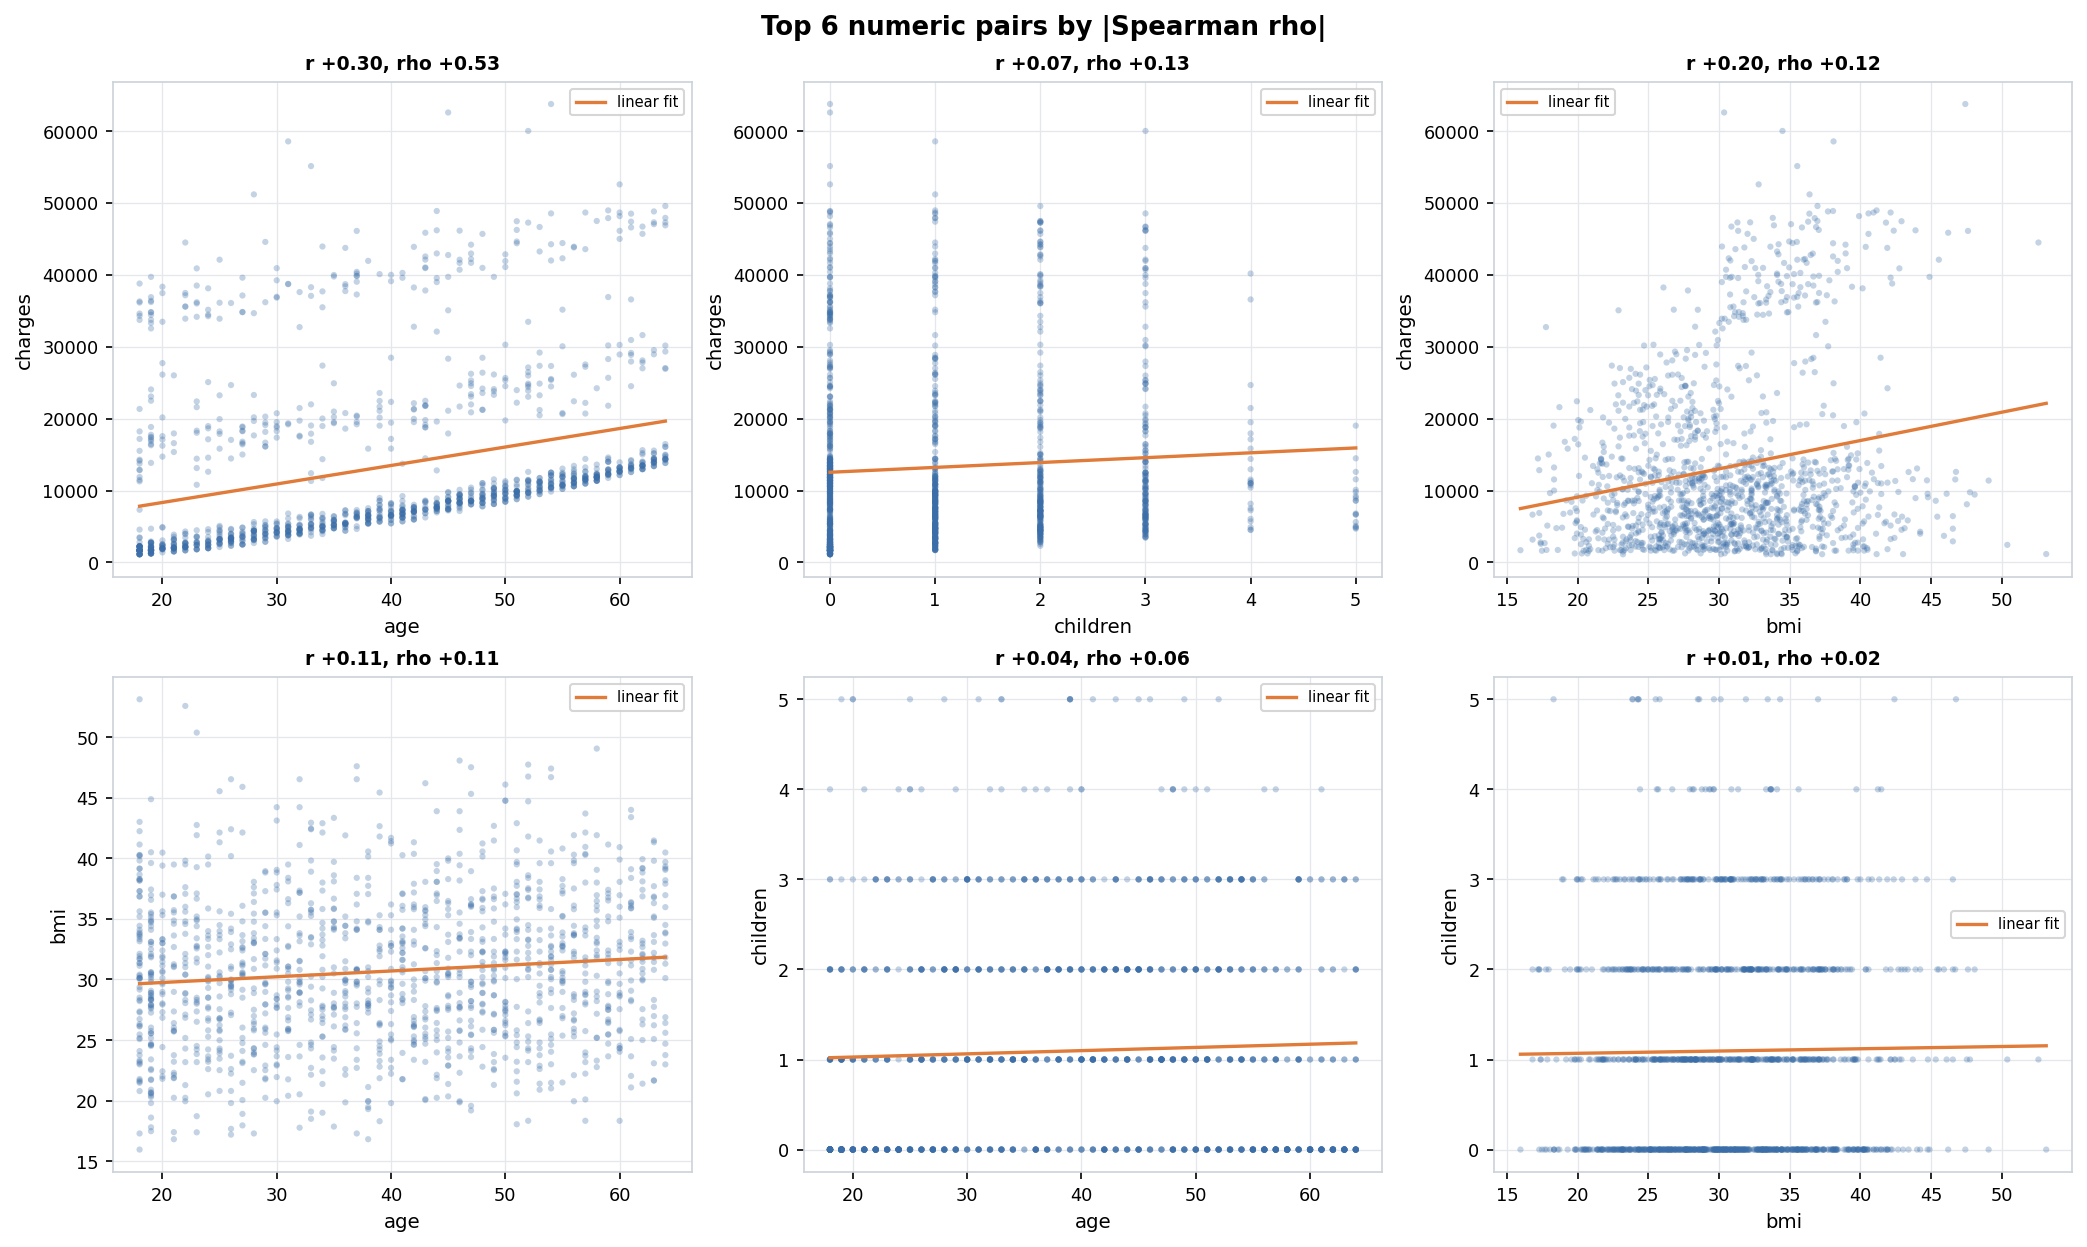

#### 'smoker' separates 'charges' the most (eta² 0.62 = share of its spread explained by the groups)
*Figure 10. 'smoker' separates 'charges' the most (eta² 0.62 = share of its spread explained by the groups).* Box plots of numeric columns split by categorical columns with up to 8 levels, for the pairs with the largest eta-squared. Descriptive coefficients only; no hypothesis tests were run.


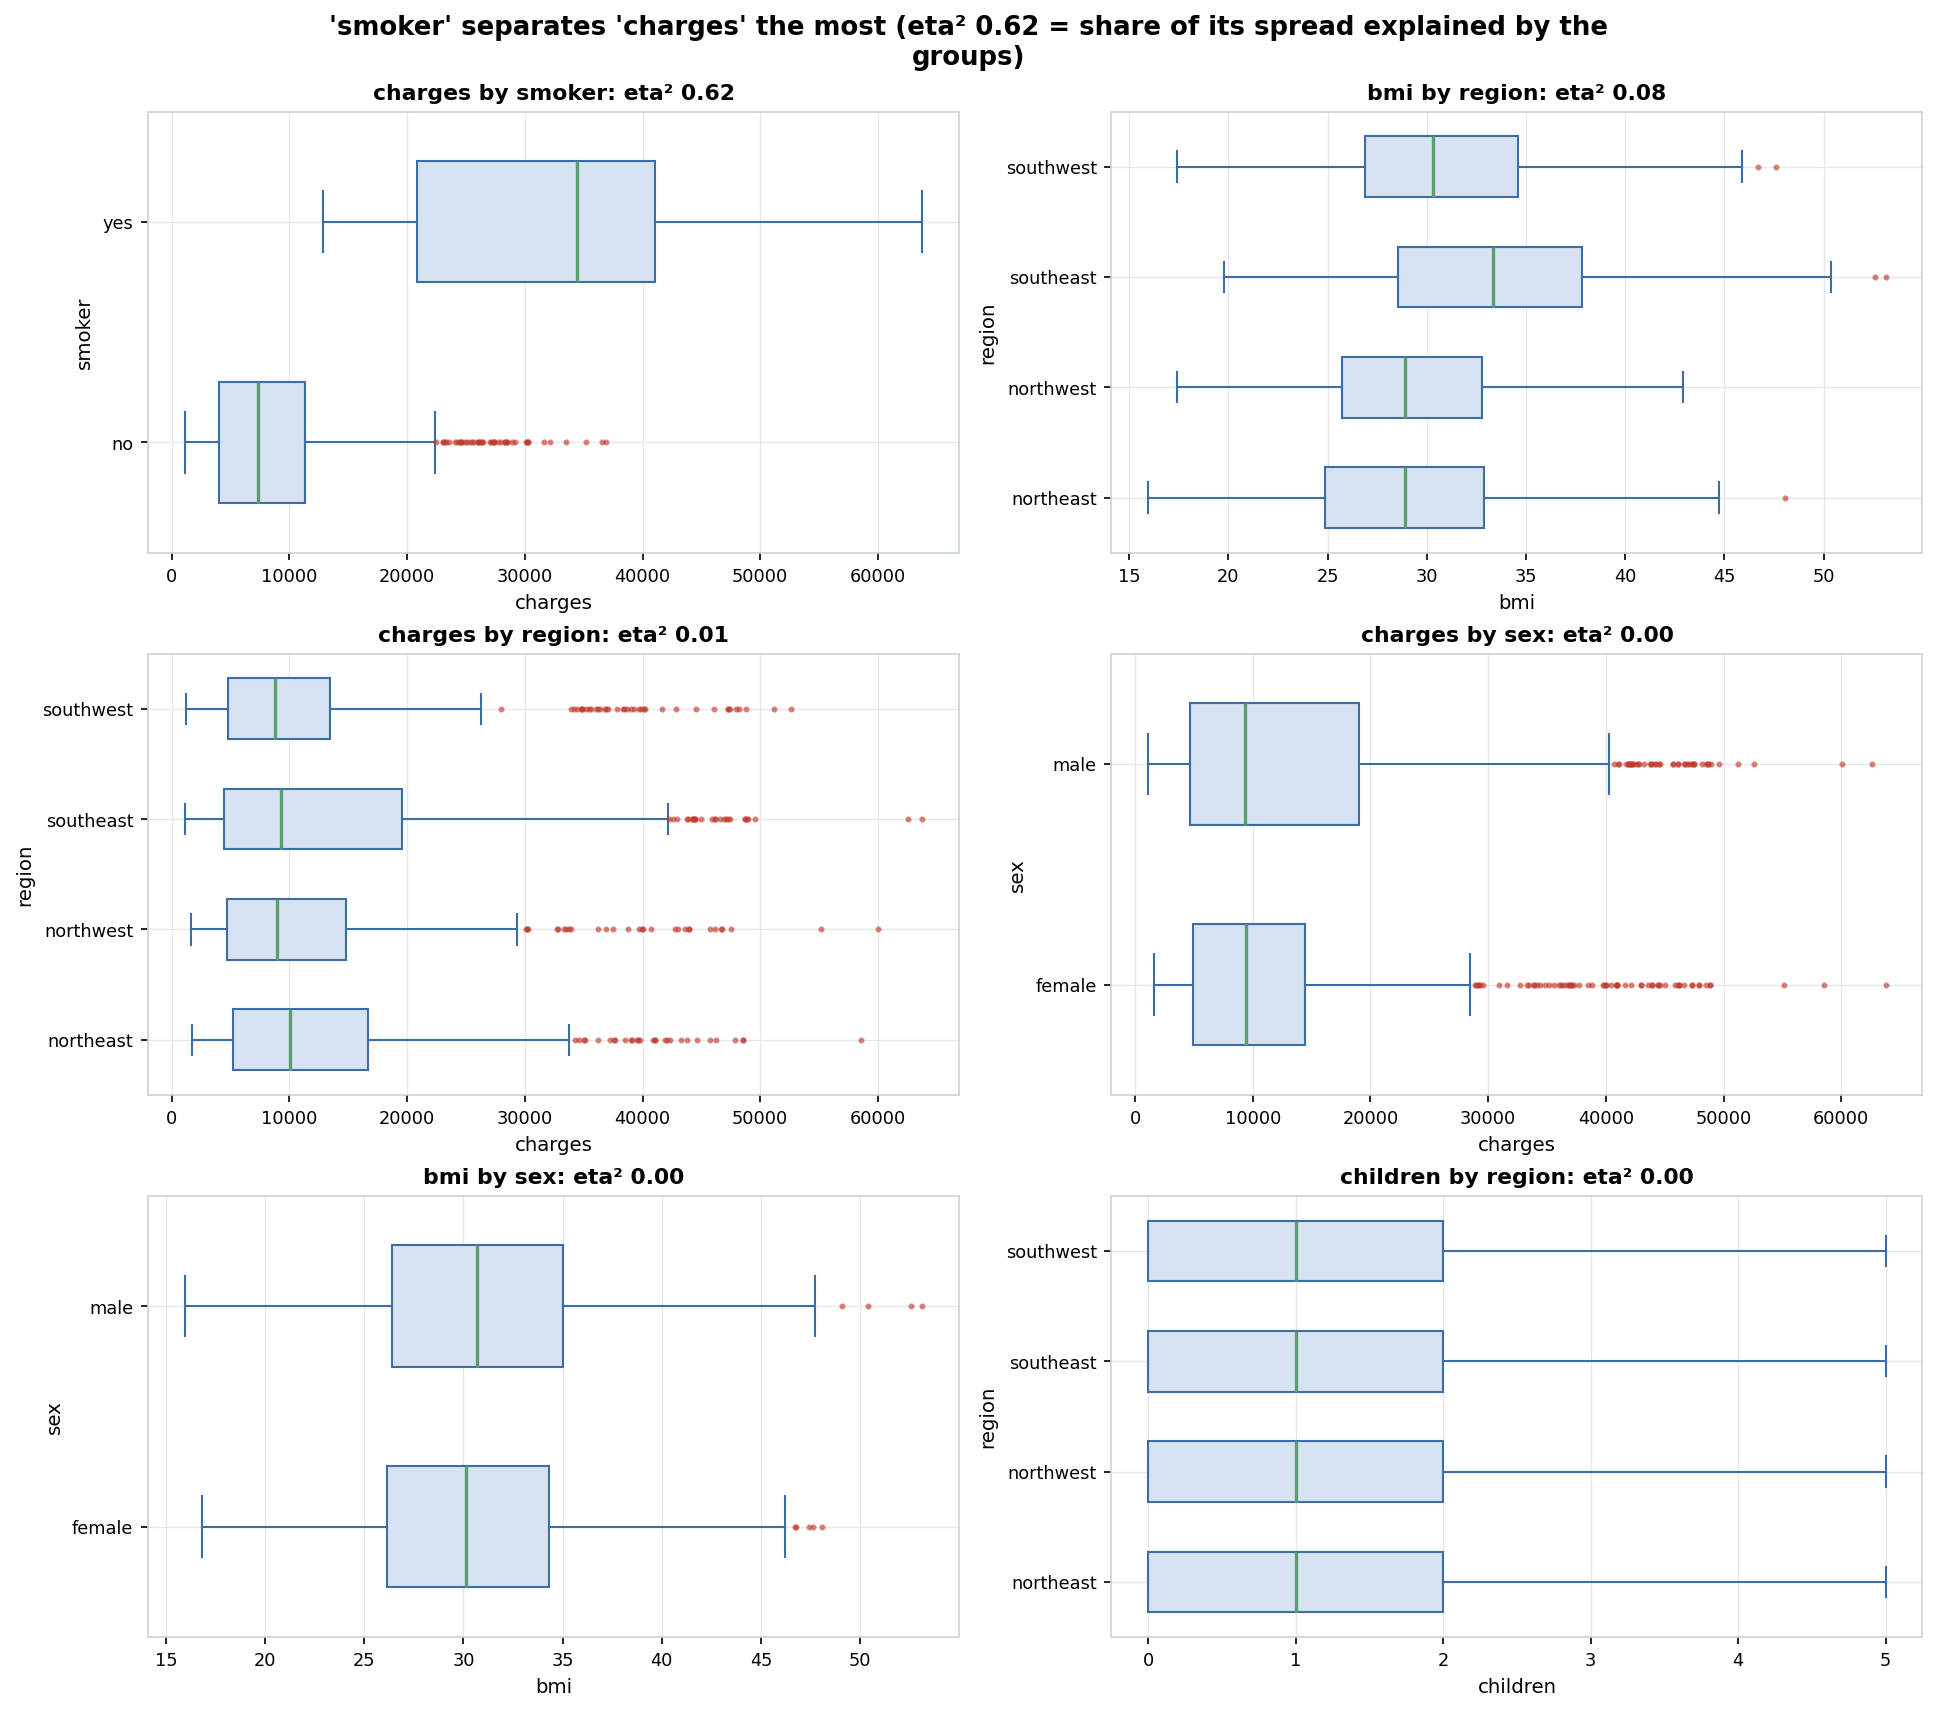

#### Strongest categorical pair: 'sex' vs 'smoker' (Cramér's V 0.07)
*Figure 11. Strongest categorical pair: 'sex' vs 'smoker' (Cramér's V 0.07).* Bias-corrected Cramér's V between categorical/binary columns: 0 = unrelated, 1 = one fully predicts the other. Descriptive coefficients only; no hypothesis tests were run.


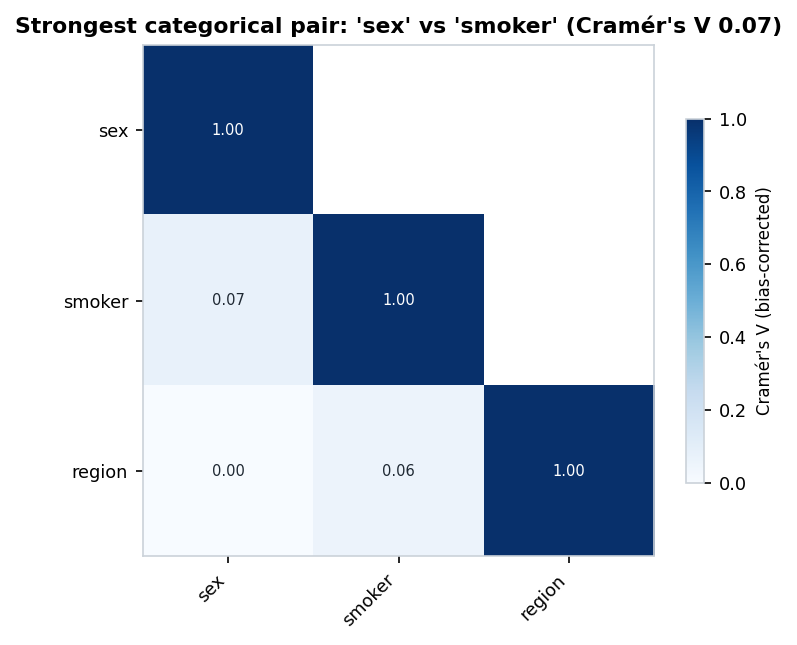

#### Level-by-level mix for the most associated categorical pairs
*Figure 12. Level-by-level mix for the most associated categorical pairs.* For each level of the first column, the share of rows in each level of the second column. Descriptive coefficients only; no hypothesis tests were run.


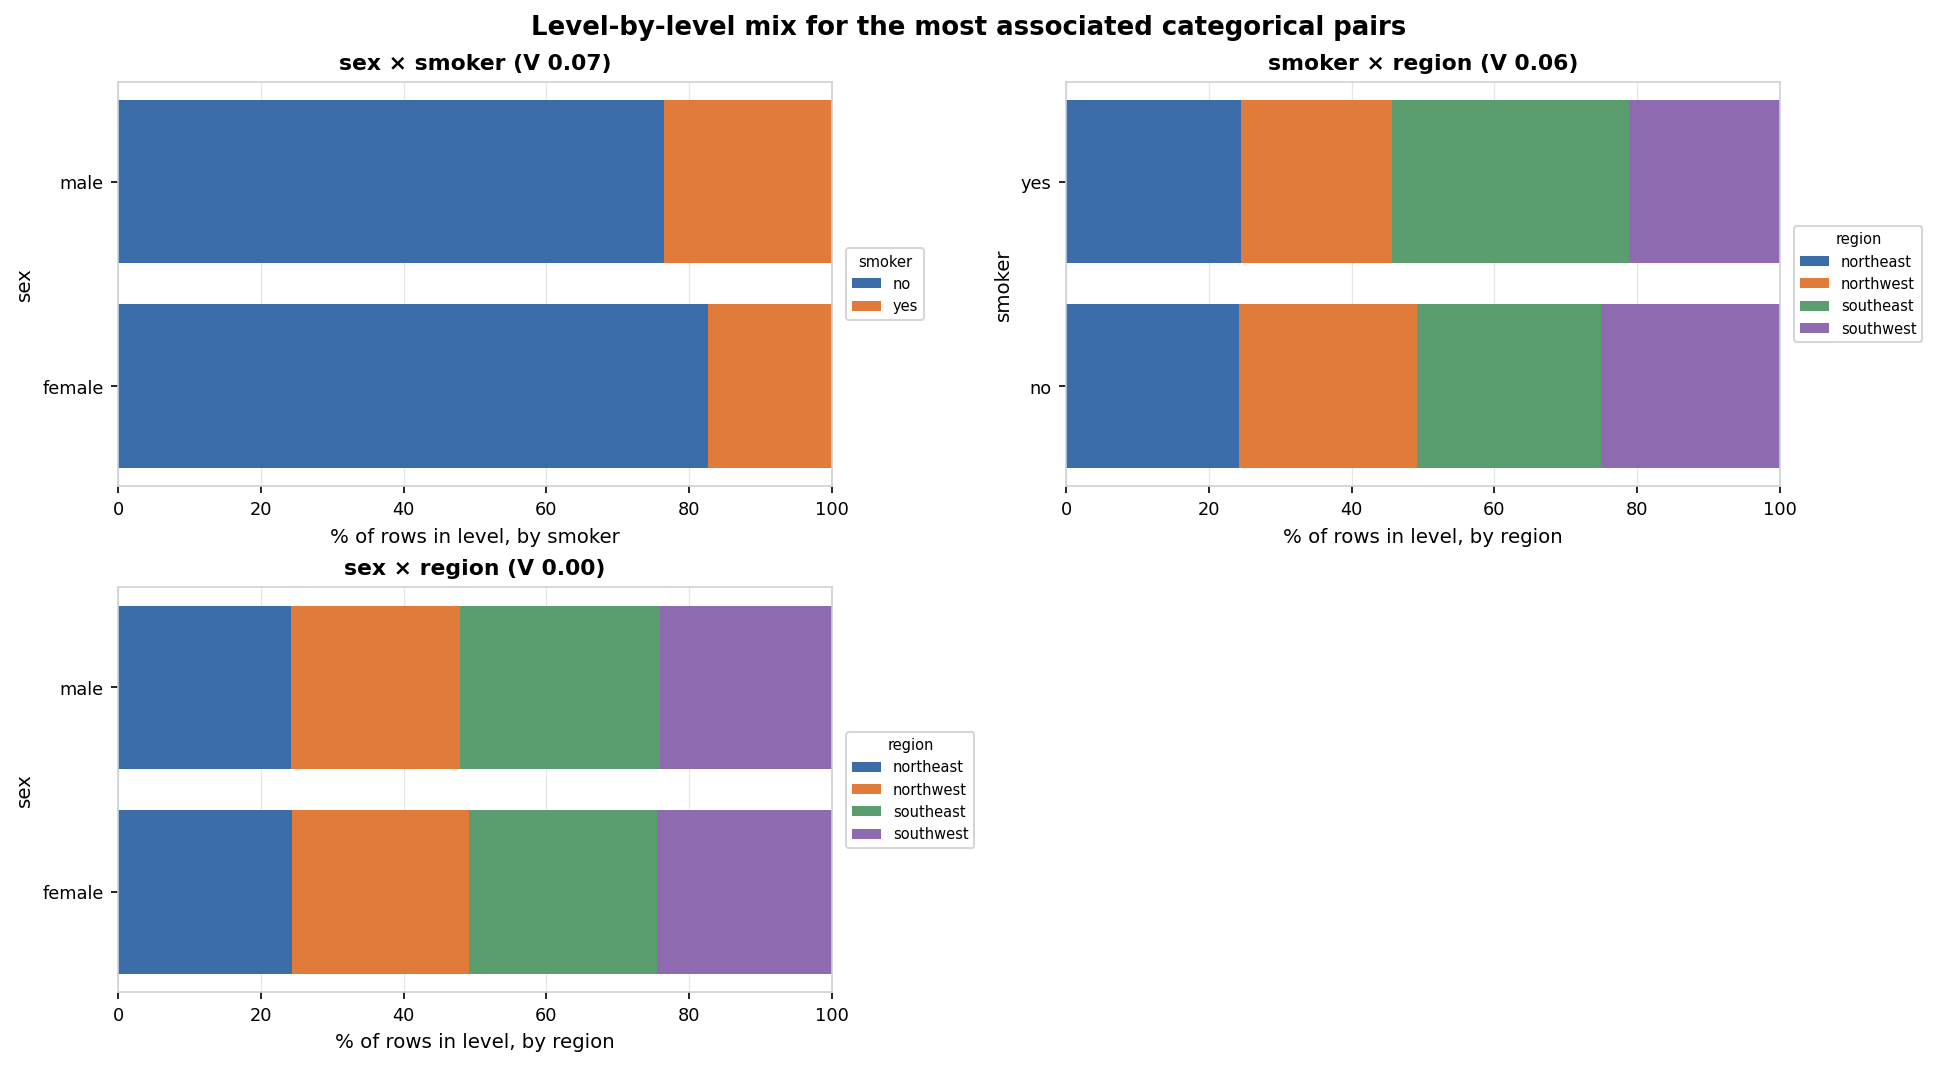

#### 'smoker' has the strongest association with 'charges' (eta² 0.62)
*Figure 13. 'smoker' has the strongest association with 'charges' (eta² 0.62).* Every feature ranked by a descriptive association with the target. Different measures are used for different column types, so compare bars of the same colour most directly. Descriptive coefficients only; no hypothesis tests were run.


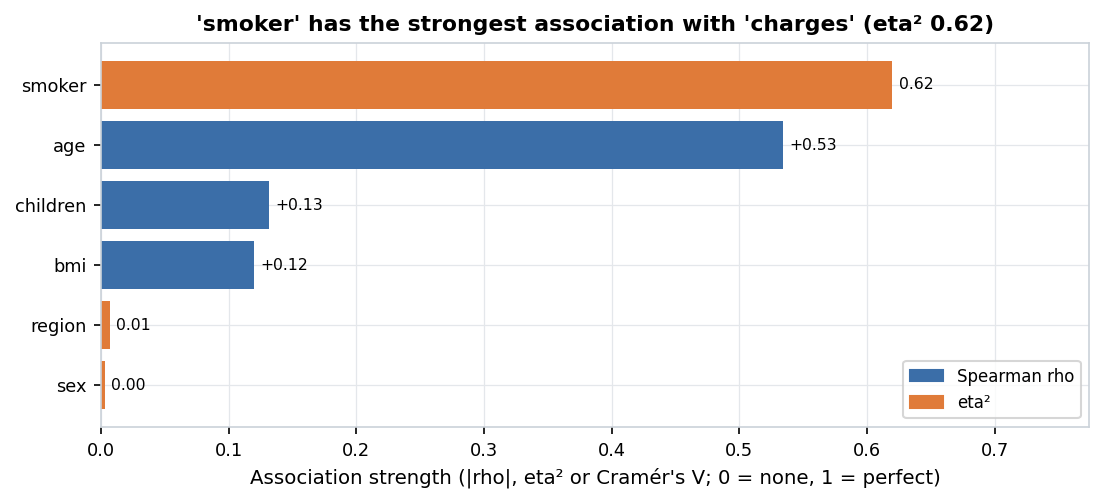

In [4]:
# Display all generated EDA figures and their interpretive captions from outputs/<dataset>/figures/
for png_path in sorted((OUT_DIR / "figures").glob("*.png")):
    display(Markdown(f"### `{png_path.name}`"))
    display(Image(filename=str(png_path)))

## 5. Normalization & Scaling Analysis
**What we did & why:** We evaluated skewness and scale disparity across all numeric columns (`ads.scaling.analyze_scaling`). Right-skewed positive columns (`|skew| > 1.0`, `min >= 0`) are recommended for `log1p` transformation, skewed columns with negative values use `yeo_johnson`, and high scale disparity triggers `zscore` standardization in `<dataset>_scaled.csv` for scale-sensitive models while keeping the primary cleaned dataset unscaled.

In [5]:
display(Markdown((OUT_DIR / "scaling_report.md").read_text(encoding="utf-8")))

# Scaling & Transformation Analysis — `insurance`

## Decision Summary

> Primary cleaned output is **not** scaled. The Phase 3 test library is rank-based or scale-invariant (Welch/Mann-Whitney, Spearman, Kruskal, chi-square), so scaling would not change results. Log transforms are recommended for columns [charges] only for plotting and for parametric/regression use. A scaled copy is provided for TA review and for any future modeling.

## Scale Disparity Across Numeric Features

- **Max standard deviation:** `12110.3597`
- **Min standard deviation:** `1.2056`
- **Scale disparity ratio (`max_std / min_std`):** `10045.33x`
- **Z-score standardization recommended for scale-sensitive models (PCA/L1/L2/KNN):** `True`

## Per-Column Transformation Recommendations

| Column | Skewness | Kurtosis | Min | Max | Std | Min >= 0 | Recommended Transform | Reason |
| :--- | ---: | ---: | ---: | ---: | ---: | :---: | :--- | :--- |
| `age` | 0.055 | -1.244 | 18 | 64 | 14.044 | True | `none` | Moderate/low skewness (skew=0.05); no non-linear transform needed. |
| `bmi` | 0.284 | -0.053 | 15.96 | 53.13 | 6.100 | True | `none` | Moderate/low skewness (skew=0.28); no non-linear transform needed. |
| `children` | 0.937 | 0.201 | 0 | 5 | 1.206 | True | `none` | Moderate/low skewness (skew=0.94); no non-linear transform needed. |
| `charges` | 1.515 | 1.604 | 1121.87 | 63770.4 | 12110.360 | True | `log1p` | Right-skewed (skew=1.52 > 1.0) with non-negative domain (min=1121.87); log1p recommended. |

## Generated Convenience Artifacts

- **Scaled CSV (TA review / downstream modeling copy):** `data\cleaned\insurance_scaled.csv`


## 6. Key Findings: Automated & Analyst Manual Insights
**What we did & why:** `ads.insights.generate_insights` evaluates deterministic rules across 7 categories (Data Quality, Distributions, Class Balance, Relationships, Cardinality/Structure, Scaling, and Modeling/Testing Implications), backing every number with an `evidence` dictionary in `insights.json`, while preserving our human-written domain analysis in the `MANUAL` block.

In [6]:
display(Markdown((OUT_DIR / "insights.md").read_text(encoding="utf-8")))

# Dataset Insights — `insurance`

_The automated insights below are generated by fixed rules from computed values (no LLM). Each number is stored with its evidence in `insights.json`. Relationship numbers are descriptive only; no hypothesis tests were run in Phase 1._

## Automated insights

### Data quality

- **MEDIUM** — 1 exact duplicate rows were removed (the first copy of each was kept).

### Distributions

- **MEDIUM** — 'charges' has many outliers: 10.4% of its values (n = 139) are beyond 1.5×IQR. They are flagged, not removed. ([figure](figures/outlier_summary.png))
- **MEDIUM** — 'charges' is right-skewed (skew = 1.51): its median (9,386.16) is below its mean (13,279.12), so a log transform is advisable for plots and parametric models. ([figure](figures/numeric_detail_charges.png))
- **MEDIUM** — 'children' is zero-inflated: 42.86% of its values are exactly zero. ([figure](figures/numeric_distributions_1.png))
- **LOW** — 'age' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_distributions_1.png))
- **LOW** — 'charges' may have 2 peaks (simple histogram heuristic), which can mean mixed sub-groups; check the plot. ([figure](figures/numeric_detail_charges.png))

### Class balance

- **INFO** — Target 'charges' is numeric, from 1,121.87 to 63,770.43 (median 9,386.16, mean 13,279.12). ([figure](figures/target_distribution.png))

### Relationships (descriptive)

- **MEDIUM** — The categorical feature most associated with target 'charges' is 'smoker' (eta² = 0.62; descriptive). ([figure](figures/target_relationships.png))
- **MEDIUM** — The numeric feature most associated with target 'charges' is 'age' (Spearman rho = +0.53; descriptive). ([figure](figures/target_relationships.png))
- **LOW** — 'age' and 'charges' rise together (Spearman rho = +0.53, Pearson r = +0.3; descriptive). ([figure](figures/top_scatter_pairs.png))

### Scaling notes

- **INFO** — Numeric columns differ a lot in spread (largest std is 10,045.33 times the smallest); z-scores are advised only for scale-sensitive methods such as regularized regression, distance-based methods or PCA.
- **INFO** — Scaling note: log1p is recommended for 'charges' (skew = 1.52) for plots and parametric models only; the main cleaned file is not transformed.

### Implications for later testing

- **MEDIUM** — Rank-based methods (Spearman, Mann-Whitney, Kruskal-Wallis) are recommended for 1 skewed or outlier-heavy column(s): 'charges'.

## Manual insights (written by the analyst)

<!-- MANUAL:START -->
- **Strongest primary effect (`smoker -> charges`):** Smokers incur dramatically higher medical charges (mean ~$32,050 vs. ~$8,441 for non-smokers, $\eta^2 = 0.62$), creating a distinct multimodal right tail in `charges`.
- **Non-linear interaction (`smoker x bmi -> charges`):** Among non-smokers, higher `bmi` increases `charges` only modestly; however, among smokers, crossing the obesity threshold (`bmi >= 30`) triggers a steep step-change jump in medical charges (clustering between $35,000 and $63,770).
- **Monotonic baseline drift (`age -> charges`):** Within each smoking/BMI stratum, `charges` increases linearly with `age` (Spearman $\rho = +0.53$) along three parallel bands corresponding to baseline plan/comorbidity tiers.
- **Duplicate row removal (`drop_duplicates: auto`):** The raw dataset contains 1 exact duplicate row (`age=19, sex=male, bmi=30.59, children=0, smoker=no, region=northwest, charges=1639.5631`), which is removed in Step 7 (`1,338 -> 1,337` rows).
- **Distributional & scaling implications:** `charges` is strongly right-skewed (`skew = +1.52`) with positive support (`min = $1,121.87`), making `log1p` transformation ideal for visualization and linear regression (`insurance_scaled.csv`), while Phase 3 should prefer Mann-Whitney U / Kruskal-Wallis and Spearman rank correlation.
- **Target findings for Phase 5 benchmark recovery:** (1) `smoker <-> charges` (large positive effect), (2) `age <-> charges` (positive monotonic correlation), (3) `bmi <-> charges` (positive correlation, amplified by `smoker`), and (4) `children <-> charges` (small positive effect).
<!-- MANUAL:END -->
